# Hackathon · Team 4 · Layout generator

**The app.** The user uploads a photo of the flat's **silhouette** and gives three things:
1. the **area** of the silhouette in m²,
2. the **number of bedrooms** they want,
3. **balcony**: yes or no.

The app answers with **5 new layouts**, invented by a model that learned from about 15,000 ResPlan plans and the relationships between their rooms. **No new data**: everything comes from ResPlan.

**The backend, step by step**

| Step | What | Where |
|---|---|---|
| 1 | Room maps in the silhouette's frame + a table of how rooms connect | **this notebook** |
| 2 | A conditional model (cVAE) that draws rooms inside a silhouette | **this notebook** |
| 3 | From the model's picture to a clean vector drawing (straight walls, doors, windows); a score for each option | next |
| 4 | From the photo to a clean silhouette | next |
| 5 | The model server | next |

`03_layout_options.ipynb` (search + fit of real plans) stays as **plan B**.

# 0. Setup

In [6]:
import json
import pickle
import time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from shapely import affinity
from shapely.geometry import Polygon
from shapely.ops import unary_union
from shapely.validation import make_valid
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import Patch

# Helper file from the ResPlan repository (MIT licence), in this folder
import resplan_utils
from resplan_utils import (plot_plan, normalize_keys, get_geometries, geometry_to_mask,
                           plan_to_graph, add_adjacency_edges)

# --- Folders: this notebook is in 01_autoencoder/notebook/ ----------------------
DATA_DIR = Path("../../data")                         # ResPlan.pkl and split.json (not on GitHub)
FIG_DIR = Path("../figures")
MODEL_DIR = Path("../models") / "layout_generator"    # files for the server and Hugging Face (not on GitHub)
for folder in [FIG_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")


# Same colours as autoencoder.ipynb (colour-blind-safe)
COLORS = {"living": "#2a78d6", "bedroom": "#eb6834", "bathroom": "#1baf7a", "kitchen": "#eda100",
          "balcony": "#e87ba4", "storage": "#008300", "stair": "#6250d6",
          "wall": "#3d3d3a", "window": "#9ec5f4", "door": "#ffffff", "front_door": "#52514e"}
resplan_utils.CATEGORY_COLORS.update(COLORS)          # plot_plan uses this dictionary

PyTorch 2.15.0+cpu, using device: cpu


# 1. The data

We keep only **clean** plans: the model learns from them.
- no augmented copies, and no plans missing from `split.json`;
- a floor in one piece, at least one bedroom, a believable area (25–400 m²);
- no quality problem in our team's `plan_tags.csv`;
- one copy of each flat (twins removed, as in `autoencoder.ipynb`).

**Units.** ResPlan coordinates are **not metres**: each plan is drawn about 256 units wide. We get the scale from the listed area and the floor (`inner`): `area_m2 = floor area × (metres per unit)²`.

In [7]:
with open(DATA_DIR / "ResPlan.pkl", "rb") as f:
    plans = pickle.load(f)
for p in plans:
    normalize_keys(p)                    # fixes a typo in some plans: "balacony" -> "balcony"

splits = json.loads((DATA_DIR / "split.json").read_text())


def as_key(x):
    # ids can be stored as numbers or as text; compare them the same way
    try:
        return int(x)
    except (TypeError, ValueError):
        return str(x)


split_of_id = {as_key(i): name for name, ids in splits.items() for i in ids}
print(f"{len(plans):,} plans loaded")

17,000 plans loaded


In [8]:
# --- Small geometry helpers -----------------------------------------------------
def valid(g):
    # some ResPlan polygons are invalid (overlapping parts); make_valid repairs them
    return g if g.is_valid else make_valid(g)


def polygons_only(g, min_area=1e-9):
    # keep only the polygons of a result (a union can also give lines and points)
    if g is None or g.is_empty:
        return []
    if g.geom_type == "Polygon":
        return [g] if g.area > min_area else []
    if hasattr(g, "geoms"):
        return [p for part in g.geoms for p in polygons_only(part, min_area)]
    return []


def apply(g, M):
    # move a Shapely geometry with a 3x3 matrix:  x' = M[0,0] x + M[0,1] y + M[0,2],  y' = M[1,0] x + M[1,1] y + M[1,2]
    return affinity.affine_transform(g, [M[0, 0], M[0, 1], M[1, 0], M[1, 1], M[0, 2], M[1, 2]])


def floor_of(plan):
    # the floor inside the walls ("inner"); used only for the scale (metres per unit)
    parts = polygons_only(unary_union([valid(g) for g in get_geometries(plan.get("inner"))]))
    return max(parts, key=lambda p: p.area) if parts else None


def silhouette_of(plan):
    # the whole flat, as an architect traces it: floor + walls + balconies
    parts = [valid(g) for key in ["inner", "wall", "balcony"] for g in get_geometries(plan.get(key))]
    if not parts:
        return None
    shape = unary_union(parts).buffer(1.0, join_style=2).buffer(-1.0, join_style=2)   # close tiny gaps (1 unit ≈ 5 cm)
    pieces = polygons_only(shape)
    if not pieces:
        return None
    biggest = max(pieces, key=lambda p: p.area)
    holes = [h for h in biggest.interiors if Polygon(h).area > 0.01 * biggest.area]   # drop tiny holes
    return Polygon(biggest.exterior, holes)

In [9]:
# One row per plan: counts, areas and the scale (metres per unit)
PLAN_KEYS = ["living", "bedroom", "bathroom", "kitchen", "balcony", "wall", "door", "window"]
rows = []
for i, p in enumerate(plans):
    pid = as_key(p.get("id", i))
    floor = floor_of(p)
    row = {"index": i, "id": pid, "split": split_of_id.get(pid, "none"),
           "listing_m2": float(p["area"]) if p.get("area") is not None else np.nan,
           "floor_parts": len(get_geometries(p.get("inner"))),
           "floor_units2": floor.area if floor is not None else 0.0}
    for k in PLAN_KEYS:
        parts = get_geometries(p.get(k))
        row[f"n_{k}"] = len(parts)
        if k in ["living", "bedroom", "bathroom", "kitchen"]:
            row[f"units2_{k}"] = sum(g.area for g in parts)
    rows.append(row)

table = pd.DataFrame(rows)
table["m_per_unit"] = np.sqrt(table["listing_m2"] / table["floor_units2"].replace(0, np.nan))
print("metres per unit:", table["m_per_unit"].describe(percentiles=[0.01, 0.5, 0.99]).round(4).to_dict())

metres per unit: {'count': 17000.0, 'mean': 0.0571, 'std': 0.015, 'min': 0.0014, '1%': 0.034, '50%': 0.0545, '99%': 0.1063, 'max': 0.2108}


In [10]:
table["remove_reason"] = ""


def flag(mask, reason):
    # Write the reason only where no earlier step has flagged the plan yet
    new = mask & (table["remove_reason"] == "")
    table.loc[new, "remove_reason"] = reason
    print(f"{reason:45s} {new.sum():6,} plans")


flag(table["split"] == "augmented", "augmented copy")
flag(table["split"] == "none", "not in split.json")
flag(table["floor_parts"] != 1, "floor in several parts")
flag(table["n_bedroom"] == 0, "no bedroom")
flag(~table["listing_m2"].between(25, 400), "area missing or outside 25-400 m²")
flag(~table["m_per_unit"].between(0.02, 0.15), "scale looks wrong")

# Quality tags made by our team (01_autoencoder/plan_tags.csv), if the file is there
TAGS_FILE = Path("../plan_tags.csv")
BAD_TAGS = ["no_window", "no_front_door", "stair_overlap", "room_gaps", "no_bedroom", "bad_area"]
if TAGS_FILE.exists():
    tags = pd.read_csv(TAGS_FILE)
    same_id = (tags["id"].astype(str).to_numpy() == table.loc[tags["idx"], "id"].astype(str).to_numpy()).mean()
    print(f"plan_tags.csv: {same_id:.0%} of its rows match our plans")
    if same_id > 0.99:
        flag(table["index"].isin(tags.loc[tags[BAD_TAGS].any(axis=1), "idx"]), "quality problem (plan_tags.csv)")
else:
    print("plan_tags.csv not found: quality tags skipped")

# Twins: the same flat published twice. Same "fingerprint" = same room counts, same % of each room type, same size.
fp = table[[f"n_{k}" for k in PLAN_KEYS]].astype(str)
for k in ["living", "bedroom", "bathroom", "kitchen"]:
    fp[f"pct_{k}"] = (table[f"units2_{k}"] / table["floor_units2"].replace(0, np.nan) * 100).round(0).astype(str)
fp["area"] = table["listing_m2"].round(0).astype(str)
table["fingerprint"] = fp.agg("|".join, axis=1)
kept = table[table["remove_reason"] == ""].assign(rank=table["split"].map({"train": 0, "val": 1, "test": 2}))
kept = kept.sort_values(["rank", "index"])            # train first, so we keep the train copy of a twin
flag(table.index.isin(kept.index[kept.duplicated("fingerprint", keep="first")]), "twin of another plan")

lib = table[table["remove_reason"] == ""].reset_index(drop=True).copy()
lib["bedrooms"] = lib["n_bedroom"]
lib["balcony"] = (lib["n_balcony"] > 0).astype(int)
is_train = (lib["split"] == "train").to_numpy()
is_val = (lib["split"] == "val").to_numpy()
is_test = (lib["split"] == "test").to_numpy()
print(f"\n{len(lib):,} clean plans:", lib["split"].value_counts().to_dict())


def plan_of(r):
    # the ResPlan plan of row r of lib
    return plans[int(lib.loc[r, "index"])]

augmented copy                                   683 plans
not in split.json                                  0 plans
floor in several parts                           118 plans
no bedroom                                         0 plans
area missing or outside 25-400 m²                 69 plans
scale looks wrong                                  0 plans
plan_tags.csv: 100% of its rows match our plans
quality problem (plan_tags.csv)                  188 plans
twin of another plan                             110 plans

15,832 clean plans: {'train': 12682, 'val': 1580, 'test': 1570}


# 2. Step 1a: silhouettes and room maps

For every plan we draw, **in the same frame**:
- the **silhouette** (floor + walls + balconies): this is what the user gives, the model's **input**;
- the **room map**: one layer per room type (living, bedroom, bathroom, kitchen, balcony), and one layer each for **walls, doors and windows**. This is what the model must **draw**.

The rooms are already in ResPlan as polygons: we only draw them as **128 × 128** images, because the model learns from images. One pixel is about **12 cm**: a wall is about 2 pixels, a door about 7, a window 8–16. The frame is the same as in `03_layout_options.ipynb`: the long side horizontal, scaled to fit with a 5% margin, centred.

Walls are drawn at their **real thickness**. Doors and windows get one extra pixel at 512 (a quarter of a pixel at 128), so they don't fade when the image is shrunk. The entrance door goes into the door layer.

We also keep, for every plan, the **frame** (matrix, width, height) and the size of one pixel in metres. We need them to turn a drawing back into metres.

In [11]:
IMG = 128         # image size: one pixel is about 12 cm
DRAW = 512        # draw big first, then shrink: smooth edges
MARGIN = 0.05
THICKEN = {"door": 1, "window": 1}                   # pixels added around thin elements at 512 px (walls: none)
ROOMS = ["living", "bedroom", "bathroom", "kitchen", "balcony"]
CHANNELS = ROOMS + ["wall", "door", "window"]        # the 8 layers the model draws


def frame_of(outline):
    # Matrix that turns the outline so the long side is horizontal and moves its corner to (0, 0).
    # Returns the matrix and the width and height of the outline in this frame.
    minx, miny, maxx, maxy = outline.bounds
    turn = np.eye(3)
    if (maxy - miny) > (maxx - minx):                  # a standing plan: turn it 90°
        turn = np.array([[0.0, -1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
    minx, miny, maxx, maxy = apply(outline, turn).bounds
    move = np.array([[1.0, 0.0, -minx], [0.0, 1.0, -miny], [0.0, 0.0, 1.0]])
    return move @ turn, maxx - minx, maxy - miny


def canvas_matrix(silhouette, draw=DRAW, margin=MARGIN):
    # Matrix from plan units to the drawing canvas, and the frame of the silhouette
    M, w, h = frame_of(silhouette)
    scale = draw * (1 - 2 * margin) / max(w, h)
    to_canvas = np.array([[scale, 0.0, (draw - w * scale) / 2],
                          [0.0, -scale, (draw + h * scale) / 2],       # minus: image rows go down
                          [0.0, 0.0, 1.0]])
    return to_canvas @ M, M, w, h, scale


def draw_layer(geoms, T, thicken=0):
    # polygons -> (IMG, IMG) image with values 0-1
    mask = geometry_to_mask([apply(g, T) for g in geoms], shape=(DRAW, DRAW))
    if thicken:
        mask = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=thicken)
    return cv2.resize(mask.astype(np.float32) / 255.0, (IMG, IMG), interpolation=cv2.INTER_AREA)


def plan_to_maps(plan):
    silhouette = silhouette_of(plan)
    T, M, w, h, scale = canvas_matrix(silhouette)
    sil = draw_layer([silhouette], T)
    geoms = {k: get_geometries(plan.get(k)) for k in CHANNELS}
    geoms["door"] = geoms["door"] + get_geometries(plan.get("front_door"))      # the entrance is a door too
    layers = np.stack([draw_layer(geoms[k], T, THICKEN.get(k, 0)) for k in CHANNELS])
    return sil, layers, M, (w, h), scale, silhouette.area

In [12]:
CACHE = DATA_DIR / f"generator_maps_{IMG}px.npz"
if CACHE.exists() and np.array_equal(np.load(CACHE)["index"], lib["index"].to_numpy()):
    cached = np.load(CACHE)
    sil_u8, maps_u8, frames, sizes = cached["sil"], cached["maps"], cached["frames"], cached["sizes"]
    scales, sil_units2 = cached["scales"], cached["sil_units2"]
    print(f"loaded from {CACHE}")
else:
    start = time.time()
    sil_u8 = np.zeros((len(lib), IMG, IMG), dtype=np.uint8)
    maps_u8 = np.zeros((len(lib), len(CHANNELS), IMG, IMG), dtype=np.uint8)
    frames, sizes = np.zeros((len(lib), 3, 3)), np.zeros((len(lib), 2))
    scales, sil_units2 = np.zeros(len(lib)), np.zeros(len(lib))
    for r in range(len(lib)):
        sil, layers, M, wh, scale, area_units = plan_to_maps(plan_of(r))
        sil_u8[r] = (sil * 255).round().astype(np.uint8)
        maps_u8[r] = (layers * 255).round().astype(np.uint8)
        frames[r], sizes[r], scales[r], sil_units2[r] = M, wh, scale, area_units
        if (r + 1) % 2000 == 0:
            print(f"{r + 1:,} / {len(lib):,} plans ({time.time() - start:.0f} s)")
    np.savez_compressed(CACHE, sil=sil_u8, maps=maps_u8, frames=frames, sizes=sizes, scales=scales,
                        sil_units2=sil_units2, index=lib["index"].to_numpy())
    print(f"drew {len(lib):,} plans in {time.time() - start:.0f} s, saved to {CACHE}")

# The numbers the user gives: the silhouette area in m², bedrooms, balcony
lib["area_m2"] = sil_units2 * lib["m_per_unit"] ** 2                     # area of the whole silhouette
lib["m_per_px"] = lib["m_per_unit"] * (DRAW / IMG) / scales              # size of one pixel, in metres
print(f"median area: listing {lib['listing_m2'].median():.0f} m² | silhouette {lib['area_m2'].median():.0f} m²")
print(f"one pixel = {lib['m_per_px'].median() * 100:.0f} cm (median)")

2,000 / 15,832 plans (24 s)
4,000 / 15,832 plans (51 s)
6,000 / 15,832 plans (78 s)
8,000 / 15,832 plans (106 s)
10,000 / 15,832 plans (134 s)
12,000 / 15,832 plans (163 s)
14,000 / 15,832 plans (193 s)
drew 15,832 plans in 233 s, saved to ..\..\data\generator_maps_128px.npz
median area: listing 109 m² | silhouette 124 m²
one pixel = 13 cm (median)


**The condition vector** (what the user asks, as numbers): bedrooms as 5 yes/no numbers (1, 2, 3, 4, 5+), balcony (0 or 1), and the area (log, scaled with the training plans). 7 numbers in total.

In [13]:
BED_MAX = 5
AREA_MEAN = float(np.log(lib.loc[is_train, "area_m2"]).mean())
AREA_STD = float(np.log(lib.loc[is_train, "area_m2"]).std())


def condition_vector(bedrooms, balcony, area_m2):
    onehot = np.zeros(BED_MAX, dtype=np.float32)
    onehot[min(max(int(bedrooms), 1), BED_MAX) - 1] = 1
    return np.r_[onehot, float(balcony), (np.log(area_m2) - AREA_MEAN) / AREA_STD].astype(np.float32)


conds = np.stack([condition_vector(b, y, a) for b, y, a in zip(lib["bedrooms"], lib["balcony"], lib["area_m2"])])
N_COND = conds.shape[1]
print("condition vectors:", conds.shape)
print(lib.loc[is_train, "bedrooms"].clip(upper=BED_MAX).value_counts().sort_index().rename("train plans per bedroom count").to_string())
print(f"plans with a balcony: {lib['balcony'].mean():.0%}")

condition vectors: (15832, 7)
bedrooms
1    1297
2    6005
3    4572
4     616
5     192
plans with a balcony: 77%


Figure saved to ..\figures\40_silhouette_and_room_maps.png


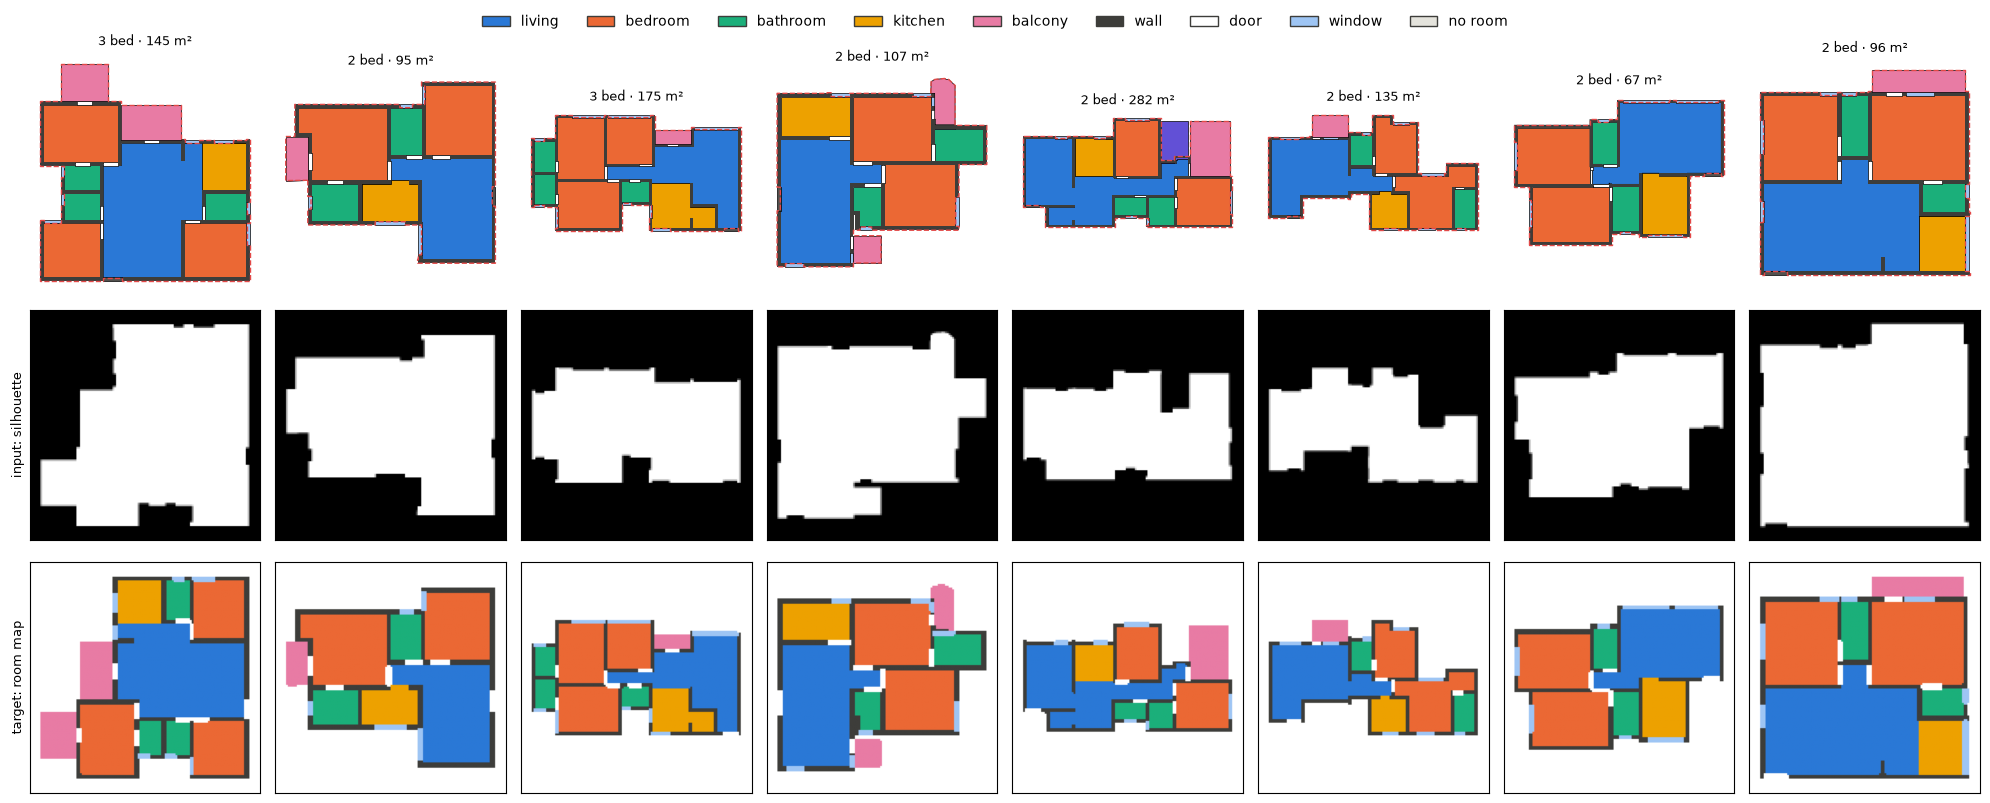

In [14]:
def to_color(maps, sil=None, room_threshold=0.5, wall_threshold=0.35):
    # (6, H, W) room map -> RGB picture: each pixel gets its strongest room type, walls on top
    maps = maps.detach().cpu().float().numpy() if torch.is_tensor(maps) else np.asarray(maps, dtype=np.float32)
    if maps.max() > 1.5:
        maps = maps / 255
    rgb = np.ones((maps.shape[1], maps.shape[2], 3))
    if sil is not None:                                      # inside the silhouette but no room: light grey
        sil = sil.detach().cpu().numpy() if torch.is_tensor(sil) else np.asarray(sil, dtype=np.float32)
        rgb[np.squeeze(sil) / (255 if np.max(sil) > 1.5 else 1) > 0.5] = to_rgb("#e4e3dc")
    rooms = maps[:len(ROOMS)]
    label, strong = rooms.argmax(0), rooms.max(0) > room_threshold
    for k, name in enumerate(ROOMS):
        rgb[(label == k) & strong] = to_rgb(COLORS[name])
    for name in ["wall", "window", "door"]:                   # doors last: white openings in the walls
        rgb[maps[CHANNELS.index(name)] > wall_threshold] = to_rgb(COLORS[name])
    return rgb


MAP_LEGEND = [Patch(facecolor=COLORS[c], edgecolor="#3d3d3a", label=c) for c in CHANNELS] + \
             [Patch(facecolor="#e4e3dc", edgecolor="#3d3d3a", label="no room")]

examples = np.where(is_train)[0][:8]
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
for c, r in enumerate(examples):
    plot_plan(plan_of(r), ax=axes[0, c], legend=False, tight=False)
    x, y = silhouette_of(plan_of(r)).exterior.xy
    axes[0, c].plot(x, y, color="#e34948", linewidth=1.0, linestyle="--")
    axes[0, c].set_title(f"{lib.loc[r, 'bedrooms']} bed · {lib.loc[r, 'area_m2']:.0f} m²", fontsize=9)
    axes[1, c].imshow(sil_u8[r], cmap="gray", vmin=0, vmax=255)
    axes[2, c].imshow(to_color(maps_u8[r], sil_u8[r]))
    for row in [1, 2]:
        axes[row, c].set_xticks([]); axes[row, c].set_yticks([])
axes[1, 0].set_ylabel("input: silhouette", fontsize=9)
axes[2, 0].set_ylabel("target: room map", fontsize=9)
fig.legend(handles=MAP_LEGEND, loc="upper center", ncol=len(MAP_LEGEND), frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
save_fig("40_silhouette_and_room_maps")
plt.show()


- the room map **sit exactly inside** the silhouette, balconies included
- the walls **thin and sharp**, and are neighbouring bedrooms **separated by a wall line**
- Can  see the **windows** (light blue) on the outer walls and the **doors** (white openings)

# 3. Step 1b: how rooms connect (from the graphs)

ResPlan's helper file builds a **graph** for each plan: one node per room, and an edge when two rooms are connected. The graph is not stored in our data file, but the function computes it from the geometry, so no new data is needed.

- `plan_to_graph`: **walkable** connections: through a door, an opening (open kitchen, arch), or the entrance.
- `add_adjacency_edges`: adds **"next to"** connections: rooms with only a wall between them.

From the graphs of many training plans we build tables:
- **opens to:** % of rooms of each type that can be walked into from a room of the other type;
- **next to:** % of rooms of each type that touch a room of the other type;
- **the entrance opens into:** which room the front door leads to;
- **room sizes** in m².

These tables are the "rules" learned from the data. In step 3 they will **score** the model's options.

In [16]:
N_GRAPHS = 3000        # graphs take time (a few minutes for 3,000); None = all training plans
RECOMPUTE_RULES = False   # False: if the table is already saved, load it instead of building the graphs again
TYPES = ["living", "kitchen", "bedroom", "bathroom", "balcony", "storage", "stair"]
WALKABLE = {"via_door", "via_opening", "direct"}
RULES_FILE = MODEL_DIR / "room_rules.json"


def share_table(counts):
    # % of rooms of each row type that are linked to at least one room of each column type
    t = pd.DataFrame({a: {b: 100 * counts[a][b] / n_rooms[a] for b in TYPES + ["front_door"]}
                      for a in TYPES if n_rooms[a] > 0}).T
    return t.loc[:, (t > 0).any()].round(0)


if RULES_FILE.exists() and not RECOMPUTE_RULES:
    rules = json.loads(RULES_FILE.read_text())
    n_rooms = Counter(rules["rooms_seen"])
    opens_table = pd.DataFrame.from_dict(rules["opens_to_percent"], orient="index")
    next_table = pd.DataFrame.from_dict(rules["next_to_percent"], orient="index")
    entrance_table = pd.Series(rules["entrance_opens_into_percent"])
    size_table = pd.DataFrame.from_dict(rules["room_m2"], orient="index")
    print(f"loaded {RULES_FILE} ({rules['n_plans']:,} plans)")
else:
    graph_rows = np.where(is_train)[0]
    if N_GRAPHS is not None and N_GRAPHS < len(graph_rows):
        graph_rows = rng.choice(graph_rows, size=N_GRAPHS, replace=False)

    n_rooms = Counter()                        # how many rooms of each type we saw
    opens_to = defaultdict(Counter)            # opens_to[a][b]: rooms of type a with a walkable link to a room of type b
    next_to = defaultdict(Counter)             # next_to[a][b]:  rooms of type a that touch a room of type b
    entrance = Counter()                       # the room types the front door leads to
    room_m2 = defaultdict(list)                # room sizes in m²
    edge_kinds = Counter()
    failed = 0
    start = time.time()
    for k, r in enumerate(graph_rows, start=1):
        plan = plan_of(r)
        try:
            G = plan_to_graph(plan)
        except Exception:
            failed += 1
            continue
        kind = lambda u, v: G[u][v].get("type")
        edge_kinds.update(kind(u, v) for u, v in G.edges())
        for n, d in G.nodes(data=True):
            if d["type"] == "front_door":
                entrance.update({G.nodes[m]["type"] for m in G[n] if kind(n, m) in WALKABLE})
                continue
            n_rooms[d["type"]] += 1
            room_m2[d["type"]].append(d["area"] * lib.loc[r, "m_per_unit"] ** 2)
            opens_to[d["type"]].update({G.nodes[m]["type"] for m in G[n] if kind(n, m) in WALKABLE})
        add_adjacency_edges(G)                 # now also "only a wall between them"
        for n, d in G.nodes(data=True):
            if d["type"] != "front_door":
                next_to[d["type"]].update({G.nodes[m]["type"] for m in G[n]})
        if k % 500 == 0:
            print(f"{k:,} / {len(graph_rows):,} graphs ({time.time() - start:.0f} s)")
    print(f"{len(graph_rows) - failed:,} graphs in {time.time() - start:.0f} s ({failed} failed)")
    print("edge types:", dict(edge_kinds))

    opens_table = share_table(opens_to)
    next_table = share_table(next_to)
    entrance_table = (pd.Series(entrance) / max(sum(entrance.values()), 1) * 100).sort_values(ascending=False).round(0)
    size_table = pd.DataFrame({t: {"rooms seen": n_rooms[t],
                                   "median m²": np.median(room_m2[t]),
                                   "small (10%) m²": np.percentile(room_m2[t], 10),
                                   "large (90%) m²": np.percentile(room_m2[t], 90)}
                               for t in TYPES if room_m2[t]}).T.round(1)
    rules = {"n_plans": int(len(graph_rows) - failed), "rooms_seen": dict(n_rooms),
             "opens_to_percent": opens_table.to_dict(orient="index"),
             "next_to_percent": next_table.to_dict(orient="index"),
             "entrance_opens_into_percent": entrance_table.to_dict(),
             "room_m2": size_table.to_dict(orient="index")}
    RULES_FILE.write_text(json.dumps(rules, indent=2, default=float))
    print(f"saved {RULES_FILE}")

print("\nThe entrance opens into (% of front doors):")
print(entrance_table.to_string())
size_table

loaded ..\models\layout_generator\room_rules.json (3,000 plans)

The entrance opens into (% of front doors):
living     99.0
stair       0.0
kitchen     0.0
balcony     0.0
bedroom     0.0


,rooms seen,median m²,small (10%) m²,large (90%) m²
living,3000.0,41.0,25.5,63.4
kitchen,3000.0,10.4,6.8,15.5
bedroom,7243.0,18.8,13.9,25.6
bathroom,7161.0,4.9,3.1,7.1
balcony,3923.0,5.4,2.9,11.2
storage,306.0,3.4,1.5,9.8
stair,81.0,5.1,1.7,11.8


Figure saved to ..\figures\41_room_relationships.png


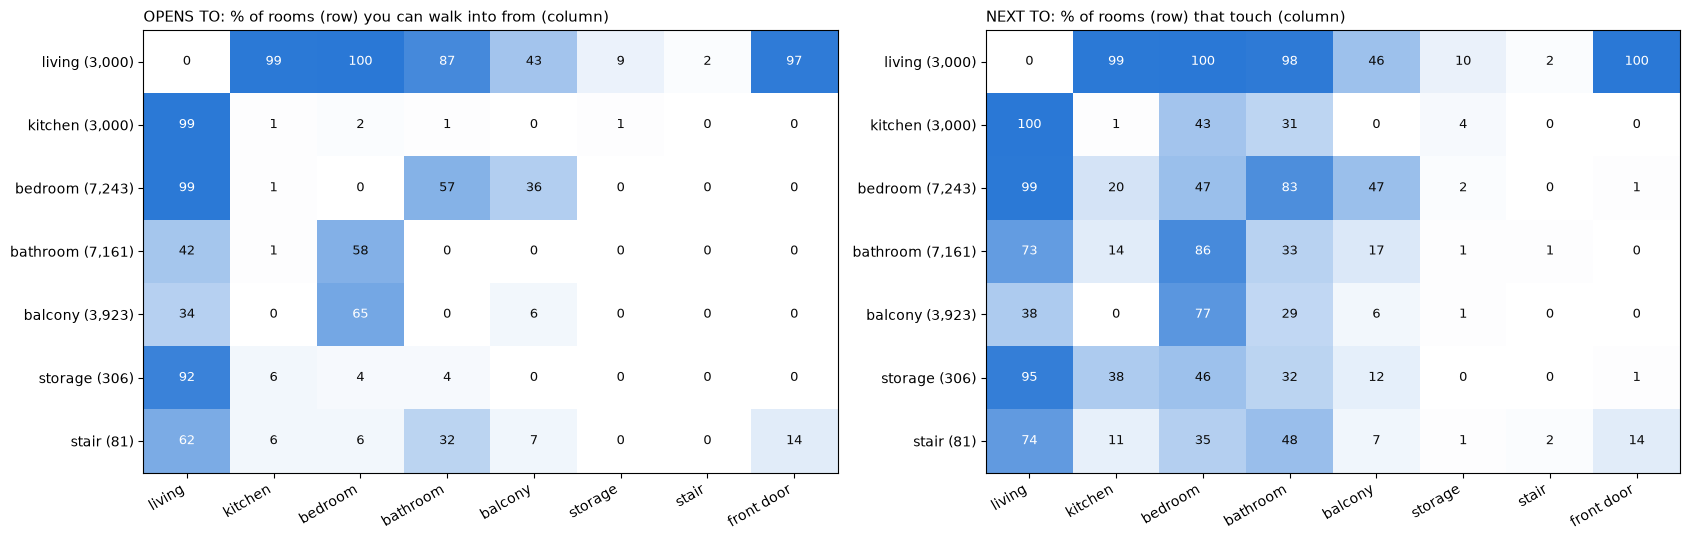

In [17]:
blue_ramp = LinearSegmentedColormap.from_list("blue", ["#ffffff", "#2a78d6"])
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, t, title in [(axes[0], opens_table, "OPENS TO: % of rooms (row) you can walk into from (column)"),
                     (axes[1], next_table, "NEXT TO: % of rooms (row) that touch (column)")]:
    ax.imshow(t.values, cmap=blue_ramp, vmin=0, vmax=100, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 60 else "#0b0b0b")
    ax.set_xticks(range(t.shape[1]), [c.replace("_", " ") for c in t.columns], rotation=30, ha="right")
    ax.set_yticks(range(t.shape[0]), [f"{i} ({n_rooms[i]:,})" for i in t.index])
    ax.set_title(title, loc="left", fontsize=11)
plt.tight_layout()
save_fig("41_room_relationships")
plt.show()

### What to look at
- Which rooms does a **bedroom** usually open to? A **bathroom**? Does the kitchen open to the living room?
- Which room does the **entrance** lead to?
- Are the room sizes **believable** for an architect? (A small bedroom of 6 m² is a warning sign for the data or for the scale.)

# 4. Step 2: the conditional model (cVAE)

**What it learns.** For each training plan it sees the room map, the silhouette and the condition (bedrooms, balcony, area).
- The **encoder** squeezes what is special about **this** layout into a code of 32 numbers.
- The **decoder** rebuilds the room map from the code + the silhouette + the condition.

**How it invents.** We give the decoder a **random code** + the user's silhouette + the user's condition. Another random code gives another layout. Five codes give five options.

Two things make it work for silhouettes:
- the decoder sees the **silhouette as an image at every size** (8, 16, 32, 64 and 128 pixels), so it knows exactly where the edges are;
- everything **outside the silhouette is erased**.

**The loss** = BCE + Dice (as in version 3: small rooms, doors and windows count too) + `BETA` × KL. The KL term keeps the codes close to random numbers, so that random codes give good layouts.

**Built in, so we train only once:**
- **Mirrors:** in every batch the plans are mirrored at random. A mirrored flat is still a good flat: 4× more examples without new data.
- **Warm-up:** the KL term starts at 0 and grows during the first epochs, so the model first learns to use the code.
- **A floor for the code** ("free bits"): each of the 32 numbers must carry a little information. Without it the model can ignore the code, and all 5 options come out the same.
- **BETA is chosen automatically:** a short trial of 3 values on 40% of the data; we keep the one with the best score (below).
- **A score every epoch** on 100 validation silhouettes: does the model draw the **bedrooms** and the **balcony** we ask for, and are the options **different**? Training **keeps the best epoch** and **stops by itself** when the score stops improving.
- **Saved and reused:** when the trained model is saved, running the notebook again **loads it** instead of training again.

In [18]:
LATENT = 32
N_OUT = len(CHANNELS)


def down(cin, cout):
    # halve the size
    return nn.Sequential(nn.Conv2d(cin, cout, 3, stride=2, padding=1), nn.ReLU())


def up(cin, cout):
    # double the size, then a normal convolution (no chequerboard dots)
    return nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU())


class LayoutCVAE(nn.Module):
    def __init__(self, latent_dim=LATENT, n_cond=N_COND, n_out=N_OUT):
        super().__init__()
        self.latent_dim = latent_dim
        # encoder: room map + silhouette -> features (128 -> 64 -> 32 -> 16 -> 8)
        self.enc = nn.Sequential(down(n_out + 1, 32), down(32, 64), down(64, 128), down(128, 128), nn.Flatten())
        self.to_mu = nn.Linear(128 * 8 * 8 + n_cond, latent_dim)
        self.to_logvar = nn.Linear(128 * 8 * 8 + n_cond, latent_dim)
        # the silhouette at 64, 32, 16 and 8 pixels, for the decoder
        self.sil64, self.sil32, self.sil16, self.sil8 = down(1, 16), down(16, 32), down(32, 64), down(64, 64)
        # decoder: code + condition -> 8x8 -> 16 -> 32 -> 64 -> 128
        self.start = nn.Sequential(nn.Linear(latent_dim + n_cond, 128 * 8 * 8), nn.ReLU())
        self.up16 = up(128 + 64, 128)
        self.up32 = up(128 + 64, 64)
        self.up64 = up(64 + 32, 32)
        self.up128 = nn.Upsample(scale_factor=2, mode="nearest")      # the last step is light: fast on a CPU
        self.out = nn.Conv2d(32 + 16 + 1, n_out, 3, padding=1)

    def encode(self, x, s, c):
        h = torch.cat([self.enc(torch.cat([x, s], 1)), c], 1)
        return self.to_mu(h), self.to_logvar(h)

    def decode(self, z, s, c):
        s64 = self.sil64(s)
        s32 = self.sil32(s64)
        s16 = self.sil16(s32)
        s8 = self.sil8(s16)
        h = self.start(torch.cat([z, c], 1)).view(-1, 128, 8, 8)
        h = self.up16(torch.cat([h, s8], 1))                            # 16 x 16
        h = self.up32(torch.cat([h, s16], 1))                           # 32 x 32
        h = self.up64(torch.cat([h, s32], 1))                           # 64 x 64
        h = self.up128(torch.cat([h, s64], 1))                          # 128 x 128
        return torch.sigmoid(self.out(torch.cat([h, s], 1))) * s      # nothing outside the silhouette

    def forward(self, x, s, c):
        mu, logvar = self.encode(x, s, c)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)        # a code near mu
        return self.decode(z, s, c), mu, logvar


#                          living bedroom bathroom kitchen balcony wall door window
CH_WEIGHTS = torch.tensor([1.0,   1.0,    2.0,     2.0,    2.0,    3.0, 8.0, 8.0]).view(1, -1, 1, 1)
FREE_BITS = 0.1       # each code number must carry at least this much information (nats)


def cvae_loss(out, x, mu, logvar, beta):
    bce = (F.binary_cross_entropy(out, x, reduction="none") * CH_WEIGHTS.to(out.device)).mean()
    inter = (out * x).sum(dim=(2, 3))
    total = out.sum(dim=(2, 3)) + x.sum(dim=(2, 3))
    dice = (1 - (2 * inter + 1) / (total + 1)).mean()                 # every layer counts the same, however small
    kl_per_number = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp())).mean(0)   # (32,) averaged over the plans
    kl_loss = kl_per_number.clamp(min=FREE_BITS).sum()                # the floor: below it, no push towards 0
    return bce + dice + beta * kl_loss, bce.item(), dice.item(), kl_per_number.sum().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())


model = LayoutCVAE()
out, mu, logvar = model(torch.zeros(2, N_OUT, IMG, IMG), torch.zeros(2, 1, IMG, IMG), torch.zeros(2, N_COND))
print(f"LayoutCVAE: output {tuple(out.shape)}, code {tuple(mu.shape)}, {n_params(model):,} parameters")

LayoutCVAE: output (2, 8, 128, 128), code (2, 32), 1,518,448 parameters


In [19]:
# Data as tensors. Room maps and silhouettes stay 0-255 (small); each batch is turned into 0-1.
# The training set points into the big arrays (no copy: the room maps are about 2 GB at 128 px).
maps_t = torch.from_numpy(maps_u8)
sil_t = torch.from_numpy(sil_u8).unsqueeze(1)
cond_t = torch.from_numpy(conds)
train_set = Subset(TensorDataset(maps_t, sil_t, cond_t), np.where(is_train)[0].tolist())
val_idx = torch.from_numpy(np.where(is_val)[0])
val_set = (maps_t[val_idx], sil_t[val_idx], cond_t[val_idx])
val_rows = np.where(is_val)[0]
score_rows = np.random.default_rng(0).choice(val_rows, size=min(100, len(val_rows)), replace=False)
print(f"train {len(train_set):,} plans | validation {len(val_set[0]):,} plans | score on {len(score_rows)} of them | "
      f"room maps in memory: {maps_u8.nbytes / 1e9:.1f} GB")


def to_device(x, s, c):
    return x.to(DEVICE).float() / 255, s.to(DEVICE).float() / 255, c.to(DEVICE)


def random_mirror(x, s):
    # the same mirror for the room maps and the silhouettes
    if torch.rand(1).item() < 0.5:
        x, s = x.flip(3), s.flip(3)
    if torch.rand(1).item() < 0.5:
        x, s = x.flip(2), s.flip(2)
    return x, s


@torch.no_grad()
def evaluate(model, data, batch_size=500):
    # validation: rebuild each plan from its own code (mu); BCE, Dice and KL
    model.eval()
    sums, n = np.zeros(3), 0
    for i in range(0, len(data[0]), batch_size):
        x, s, c = to_device(*(t[i:i + batch_size] for t in data))
        mu, logvar = model.encode(x, s, c)
        _, bce, dice, kl = cvae_loss(model.decode(mu, s, c), x, mu, logvar, 0.0)
        sums += np.array([bce, dice, kl]) * len(x)
        n += len(x)
    return dict(zip(["val_bce", "val_dice", "val_kl"], sums / n))

train 12,682 plans | validation 1,580 plans | score on 100 of them | room maps in memory: 2.1 GB


**Counting in a picture** (for the score). Each pixel gets its strongest room type; bedroom pixels that are not wall are grouped into pieces; a piece of at least 6 m² is a bedroom. A balcony counts if it covers at least 1 m².

**The score** = share of options with the right number of bedrooms + share with the balcony as asked (best = 2). If the options are almost the same (less than 5% of the pixels differ), the score loses 1: five identical options are useless.

In [20]:
MIN_DIFFERENT = 0.05


def count_in_map(maps, m_per_px, min_bedroom_m2=6.0, min_balcony_m2=1.0):
    maps = maps.numpy() if torch.is_tensor(maps) else np.asarray(maps, dtype=np.float32)
    if maps.max() > 1.5:
        maps = maps / 255
    rooms = maps[:len(ROOMS)]
    label, strong = rooms.argmax(0), rooms.max(0) > 0.5
    not_wall = maps[CHANNELS.index("wall")] < 0.35
    bed = ((label == ROOMS.index("bedroom")) & strong & not_wall).astype(np.uint8)
    _, _, stats, _ = cv2.connectedComponentsWithStats(bed, connectivity=4)
    bedrooms = int((stats[1:, cv2.CC_STAT_AREA] * m_per_px ** 2 >= min_bedroom_m2).sum())
    balcony_m2 = ((label == ROOMS.index("balcony")) & strong).sum() * m_per_px ** 2
    return bedrooms, int(balcony_m2 >= min_balcony_m2)


def label_map(maps, sil):
    # one room type per pixel inside the silhouette (-1 = no room), to compare two layouts
    maps = maps.numpy() if torch.is_tensor(maps) else maps
    label = np.where(maps[:len(ROOMS)].max(0) > 0.5, maps[:len(ROOMS)].argmax(0), -1)
    return label[np.asarray(sil) > 127]


@torch.no_grad()
def generate(model, sil, cond, n=5, seed=None):
    # sil: (128, 128) values 0-255; cond: (7,)  ->  n invented room maps (n, 8, 128, 128), values 0-1
    model.eval()
    gen = torch.Generator().manual_seed(seed) if seed is not None else None
    z = torch.randn(n, model.latent_dim, generator=gen)
    s = torch.as_tensor(np.asarray(sil), dtype=torch.float32).view(1, 1, IMG, IMG).repeat(n, 1, 1, 1) / 255
    c = torch.as_tensor(np.asarray(cond), dtype=torch.float32).view(1, -1).repeat(n, 1)
    return model.decode(z.to(DEVICE), s.to(DEVICE), c.to(DEVICE)).cpu()


def request_score(model, rows, n=3):
    # does the model draw what we ask, and are the options different?
    beds_ok, balcony_ok, different = [], [], []
    for k, r in enumerate(rows):
        options = generate(model, sil_u8[r], conds[r], n=n, seed=k)       # the same codes every time: a fair comparison
        asked_beds = min(int(lib.loc[r, "bedrooms"]), BED_MAX)
        for o in options:
            beds, balcony = count_in_map(o, lib.loc[r, "m_per_px"])
            beds_ok.append(min(beds, BED_MAX) == asked_beds)
            balcony_ok.append(balcony == lib.loc[r, "balcony"])
        labels = [label_map(o, sil_u8[r]) for o in options]
        different.append(np.mean([(labels[i] != labels[j]).mean() for i in range(n) for j in range(i + 1, n)]))
    result = {"bedrooms_right": float(np.mean(beds_ok)), "balcony_right": float(np.mean(balcony_ok)),
              "different": float(np.mean(different))}
    result["score"] = result["bedrooms_right"] + result["balcony_right"] - (1.0 if result["different"] < MIN_DIFFERENT else 0.0)
    return result

In [21]:
def train_cvae(model, dataset, epochs, beta, warmup=5, patience=None, save_to=None, lr=1e-3, batch_size=128, verbose=True):
    # Trains, scores every epoch, keeps the best epoch (saved to save_to), stops after `patience` epochs without progress
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    history, best, best_epoch = [], -np.inf, 0
    start = time.time()
    for epoch in range(1, epochs + 1):
        b = beta * min(1.0, epoch / warmup)                             # KL warm-up
        model.train()
        total = 0.0
        for x, s, c in loader:
            x, s, c = to_device(x, s, c)
            x, s = random_mirror(x, s)
            out, mu, logvar = model(x, s, c)
            loss, *_ = cvae_loss(out, x, mu, logvar, b)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
        row = {"epoch": epoch, "beta": b, "train_loss": total / len(dataset),
               **evaluate(model, val_set), **request_score(model, score_rows)}
        history.append(row)
        if verbose:
            print(f"epoch {epoch:2d}  val BCE {row['val_bce']:.4f}  Dice {row['val_dice']:.3f}  KL {row['val_kl']:5.1f}  |  "
                  f"bedrooms right {row['bedrooms_right']:.0%}  balcony right {row['balcony_right']:.0%}  "
                  f"different {row['different']:.0%}  score {row['score']:.2f}  ({time.time() - start:.0f} s)")
            if epoch == 1:
                print(f"   -> about {(time.time() - start) * epochs / 60:.0f} minutes for {epochs} epochs (less if it stops early)")
        if epoch >= warmup and row["score"] > best:
            best, best_epoch = row["score"], epoch
            if save_to is not None:
                torch.save(model.state_dict(), save_to)
        if patience and epoch - max(best_epoch, warmup) >= patience:
            print(f"no better score for {patience} epochs: stop")
            break
    if save_to is not None and best_epoch > 0:
        model.load_state_dict(torch.load(save_to, map_location=DEVICE))      # keep the best epoch
    return model, history, best_epoch

In [22]:
RETRAIN = False                      # False: if a trained model is saved, load it instead of training again
BETAS = [0.0005, 0.002, 0.008]       # tried automatically; the best one is used for the full training
TRIAL_EPOCHS, TRIAL_SHARE = 4, 0.4   # the trial: 4 epochs on 40% of the training plans
MAX_EPOCHS, PATIENCE = 40, 8         # the full training stops earlier if the score stops improving
WEIGHTS = MODEL_DIR / "layout_cvae.pt"
TRAIN_LOG = MODEL_DIR / "layout_cvae_training.json"

if WEIGHTS.exists() and TRAIN_LOG.exists() and not RETRAIN:
    log = json.loads(TRAIN_LOG.read_text())
    BETA, history, best_epoch, trial_table = log["beta"], log["history"], log["best_epoch"], pd.DataFrame(log["trials"])
    cvae = LayoutCVAE().to(DEVICE)
    cvae.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE))
    print(f"loaded the trained model: BETA {BETA}, best epoch {best_epoch} of {len(history)}")
else:
    start = time.time()
    trial_rows = np.random.default_rng(1).choice(len(train_set), size=int(TRIAL_SHARE * len(train_set)), replace=False)
    trial_set = Subset(train_set, trial_rows.tolist())
    trials = []
    for beta in BETAS:
        _, h, _ = train_cvae(LayoutCVAE(), trial_set, epochs=TRIAL_EPOCHS, beta=beta, warmup=2, verbose=False)
        trials.append({"BETA": beta, **{k: h[-1][k] for k in ["val_bce", "val_dice", "val_kl", "bedrooms_right",
                                                             "balcony_right", "different", "score"]}})
        print(f"trial BETA {beta}: score {trials[-1]['score']:.2f}, bedrooms right {trials[-1]['bedrooms_right']:.0%}, "
              f"different {trials[-1]['different']:.0%}  ({time.time() - start:.0f} s)")
    trial_table = pd.DataFrame(trials)
    BETA = float(trial_table.loc[trial_table["score"].idxmax(), "BETA"])
    print(f"\nchosen BETA = {BETA}. Full training:")
    cvae, history, best_epoch = train_cvae(LayoutCVAE(), train_set, epochs=MAX_EPOCHS, beta=BETA,
                                           patience=PATIENCE, save_to=WEIGHTS)
    TRAIN_LOG.write_text(json.dumps({"beta": BETA, "best_epoch": best_epoch, "history": history,
                                     "trials": trial_table.to_dict(orient="records")}, indent=2, default=float))
    print(f"best epoch {best_epoch}, saved to {WEIGHTS} ({(time.time() - start) / 60:.0f} minutes in total)")
trial_table.round(3)

trial BETA 0.0005: score 1.05, bedrooms right 30%, different 12%  (214 s)
trial BETA 0.002: score 0.97, bedrooms right 32%, different 17%  (437 s)
trial BETA 0.008: score 1.09, bedrooms right 36%, different 17%  (640 s)

chosen BETA = 0.008. Full training:
epoch  1  val BCE 0.9047  Dice 0.773  KL   3.1  |  bedrooms right 21%  balcony right 20%  different 1%  score -0.59  (119 s)
   -> about 79 minutes for 40 epochs (less if it stops early)
epoch  2  val BCE 0.8623  Dice 0.671  KL   6.9  |  bedrooms right 35%  balcony right 71%  different 40%  score 1.06  (233 s)
epoch  3  val BCE 0.8107  Dice 0.561  KL  12.5  |  bedrooms right 34%  balcony right 83%  different 50%  score 1.17  (349 s)
epoch  4  val BCE 0.7836  Dice 0.505  KL  14.1  |  bedrooms right 37%  balcony right 86%  different 58%  score 1.23  (467 s)
epoch  5  val BCE 0.7819  Dice 0.459  KL  16.2  |  bedrooms right 35%  balcony right 84%  different 59%  score 1.18  (589 s)
epoch  6  val BCE 0.7647  Dice 0.430  KL  14.4  |  bedro

,BETA,val_bce,val_dice,val_kl,bedrooms_right,balcony_right,different,score
0,0.000,0.897,0.751,2.573,0.300,0.750,0.120,1.050
1,0.002,0.902,0.748,2.856,0.317,0.657,0.169,0.973
2,0.008,0.900,0.750,2.408,0.360,0.733,0.174,1.093


### What we see (the BETA trial)

| BETA | bedrooms right | balcony right | options differ | score |
|---|---|---|---|---|
| 0.0005 | 30% | 75% | 12% | 1.05 |
| 0.002 | 32% | 66% | 17% | 0.97 |
| **0.008** | **36%** | 73% | 17% | **1.09** |

- The trial is short (4 epochs on 40% of the data), so the drawing quality (BCE, Dice) is almost the same for the three values. The differences are small and partly noise (100 plans, 3 options each).
- **BETA = 0.008 was chosen:** it gave the most bedrooms right, and different options.
- **A trend:** the higher BETA, the more bedrooms right (30% → 32% → 36%). A higher BETA forces the model to follow the request instead of the random code. The best value was at the **edge** of the range we tried, so a higher BETA (e.g. 0.02–0.03) may be even better.
- **In the full training** with BETA = 0.008: balcony right up to 99%, bedrooms right about 40%, best score 1.39 (epoch 20).

# 5. Does it work?

Four checks, all with the **best epoch**:
1. **Learning curves:** loss, KL and the score, epoch by epoch.
2. **Rebuilding:** can the model rebuild a plan it has never seen, from its own code?
3. **Inventing:** 5 random codes for the same silhouette: are the 5 layouts good and different?
4. **Following the request:** the same silhouette with 1–4 bedrooms, with and without a balcony; then the numbers on 200 validation plans.

Figure saved to ..\figures\42_cvae_training.png


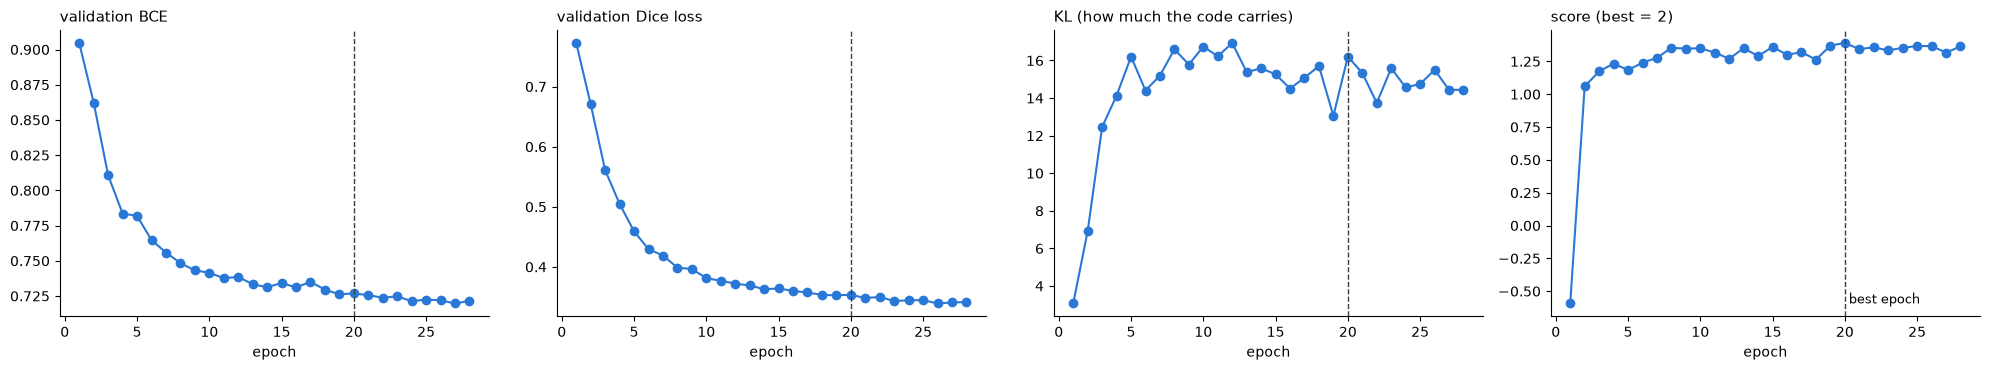

Figure saved to ..\figures\43_cvae_rebuilt.png


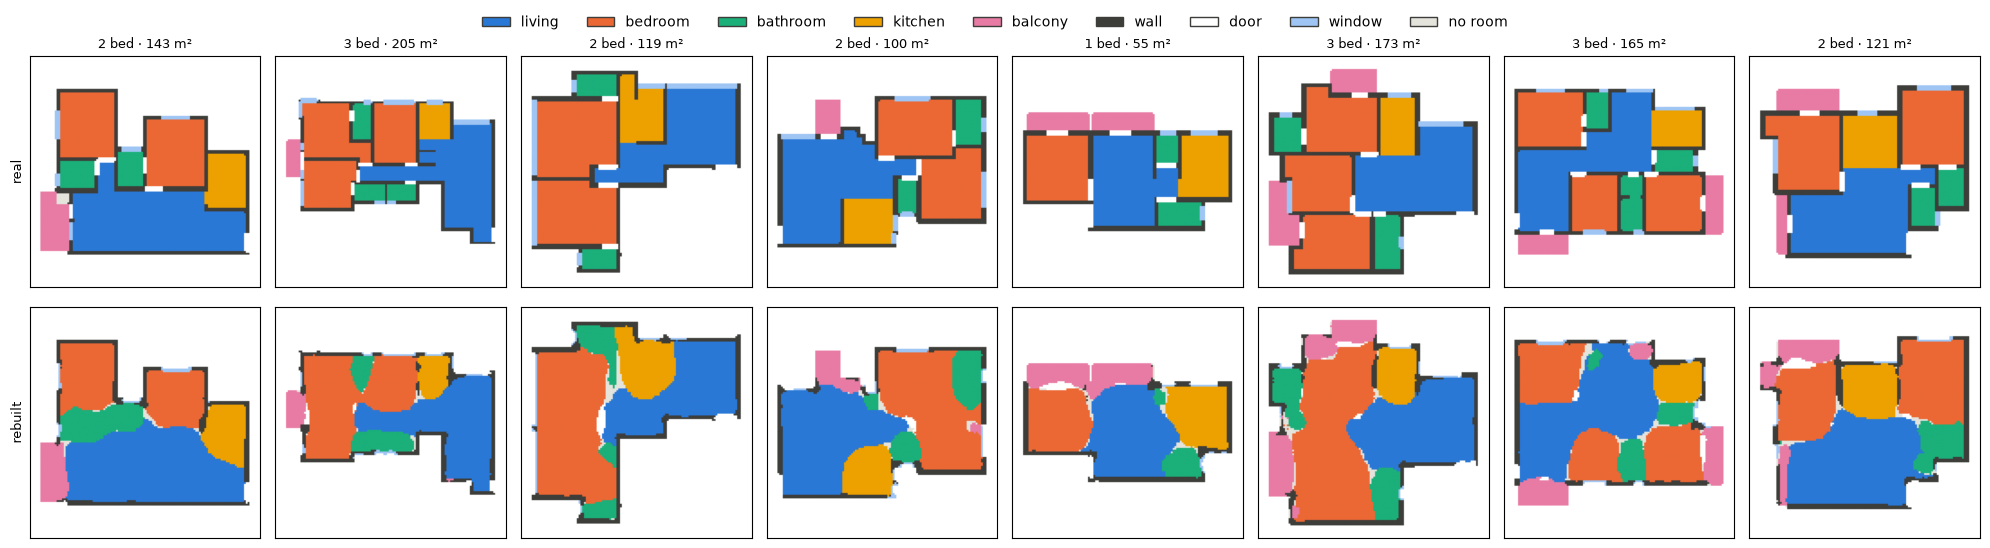

In [23]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, col, title in [(axes[0], "val_bce", "validation BCE"), (axes[1], "val_dice", "validation Dice loss"),
                       (axes[2], "val_kl", "KL (how much the code carries)"), (axes[3], "score", "score (best = 2)")]:
    ax.plot(hist["epoch"], hist[col], marker="o", color="#2a78d6")
    ax.axvline(best_epoch, color="#3d3d3a", linestyle="--", linewidth=1)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("epoch")
    ax.spines[["top", "right"]].set_visible(False)
axes[3].text(best_epoch, hist["score"].min(), " best epoch", fontsize=9)
plt.tight_layout()
save_fig("42_cvae_training")
plt.show()


@torch.no_grad()
def rebuild(model, rows):
    model.eval()
    x, s, c = to_device(maps_t[rows], sil_t[rows], cond_t[rows])
    mu, _ = model.encode(x, s, c)
    return model.decode(mu, s, c).cpu()


sample_rows = val_rows[:8]
rebuilt = rebuild(cvae, sample_rows)
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for c, r in enumerate(sample_rows):
    axes[0, c].imshow(to_color(maps_u8[r], sil_u8[r]))
    axes[1, c].imshow(to_color(rebuilt[c], sil_u8[r]))
    axes[0, c].set_title(f"{lib.loc[r, 'bedrooms']} bed · {lib.loc[r, 'area_m2']:.0f} m²", fontsize=9)
    for row in [0, 1]:
        axes[row, c].set_xticks([]); axes[row, c].set_yticks([])
axes[0, 0].set_ylabel("real", fontsize=9)
axes[1, 0].set_ylabel("rebuilt", fontsize=9)
fig.legend(handles=MAP_LEGEND, loc="upper center", ncol=len(MAP_LEGEND), frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
save_fig("43_cvae_rebuilt")
plt.show()

Figure saved to ..\figures\44_cvae_invented.png


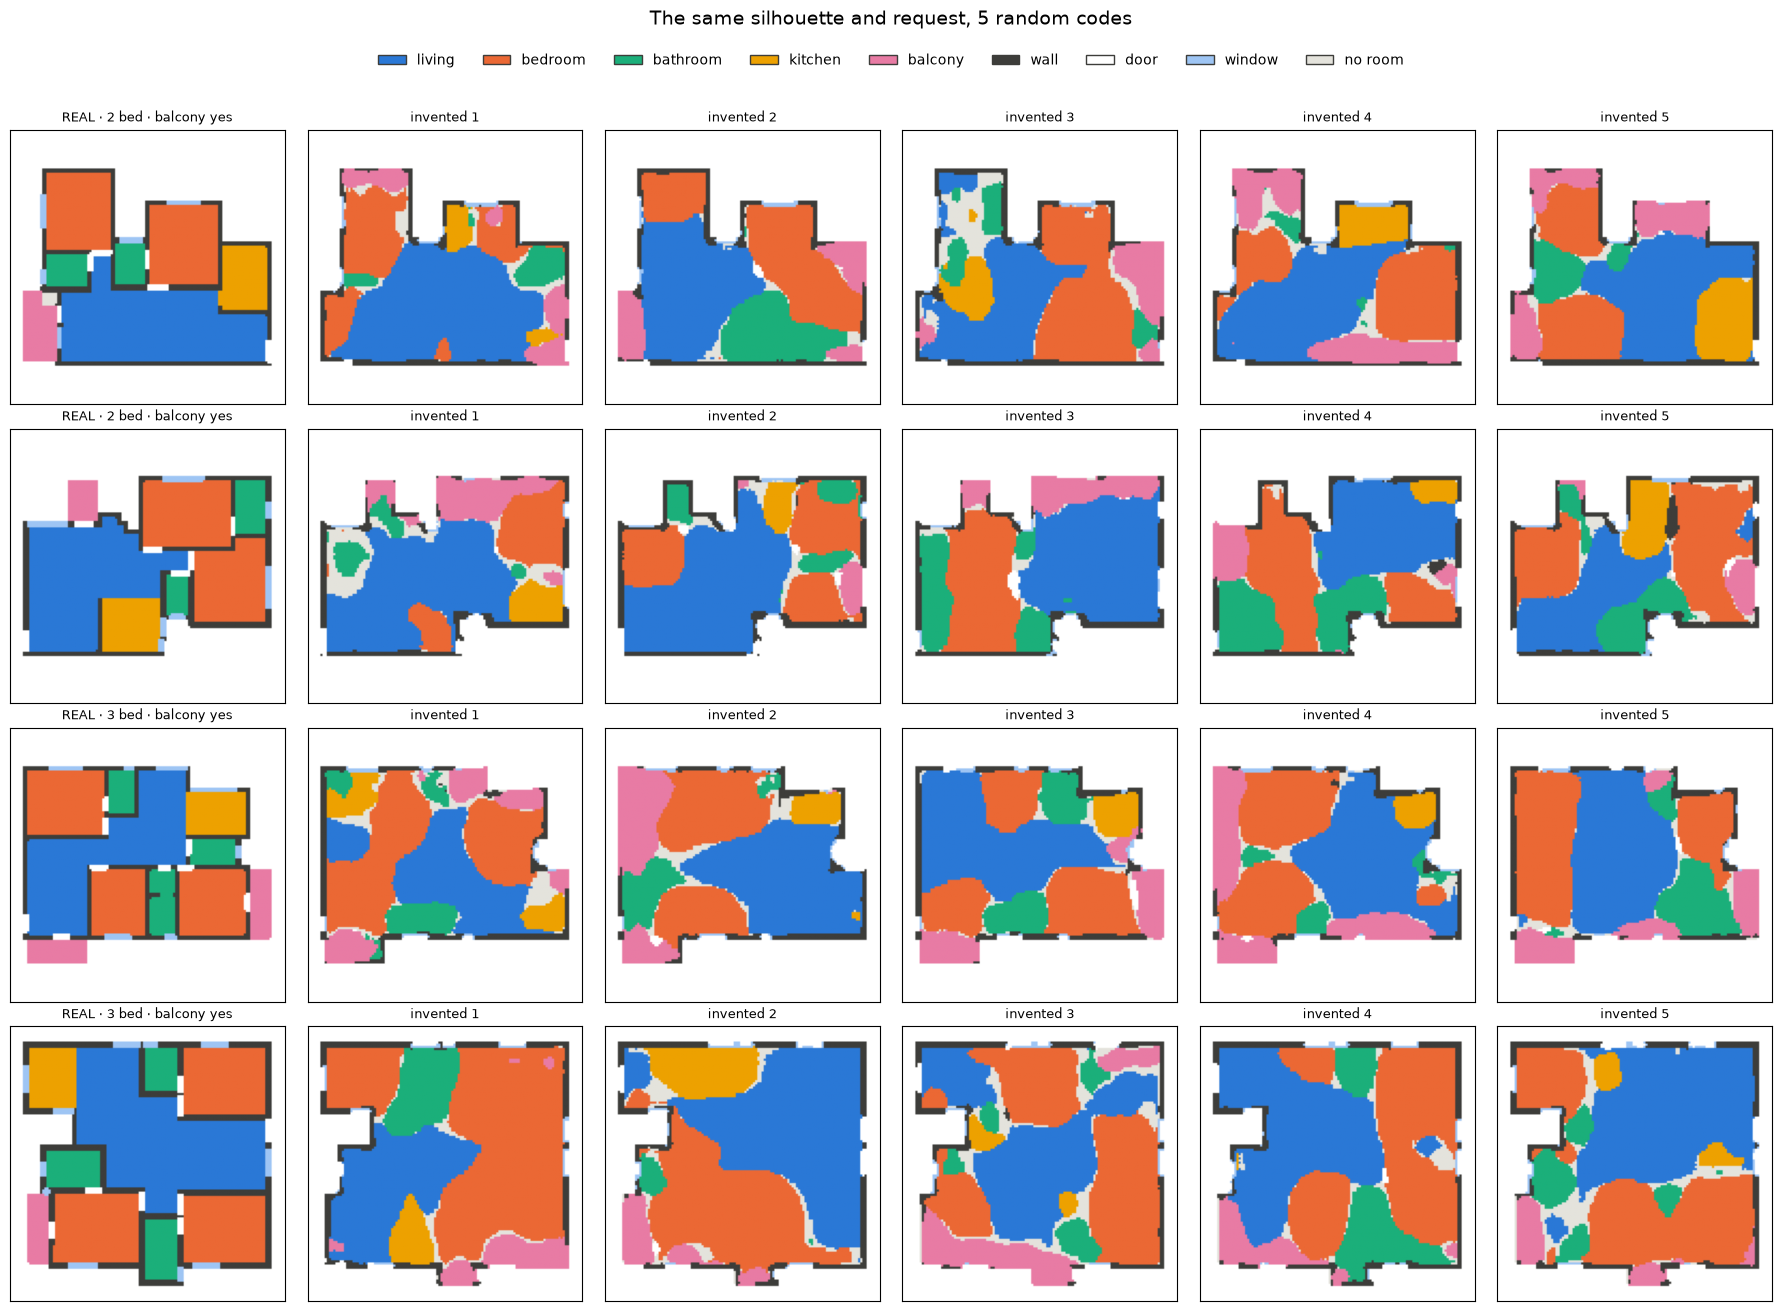

In [24]:
# Inventing: 4 validation silhouettes (never seen), each with its own condition, 5 random codes
fig, axes = plt.subplots(4, 6, figsize=(18, 12.5))
for row, r in enumerate(val_rows[[0, 3, 6, 9]]):
    axes[row, 0].imshow(to_color(maps_u8[r], sil_u8[r]))
    axes[row, 0].set_title(f"REAL · {lib.loc[r, 'bedrooms']} bed · balcony {'yes' if lib.loc[r, 'balcony'] else 'no'}", fontsize=9)
    options = generate(cvae, sil_u8[r], conds[r], n=5, seed=row)
    for c in range(5):
        axes[row, c + 1].imshow(to_color(options[c], sil_u8[r]))
        axes[row, c + 1].set_title(f"invented {c + 1}", fontsize=9)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
fig.legend(handles=MAP_LEGEND, loc="upper center", ncol=len(MAP_LEGEND), frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("The same silhouette and request, 5 random codes", y=1.045, fontsize=14)
plt.tight_layout()
save_fig("44_cvae_invented")
plt.show()

Figure saved to ..\figures\45_cvae_follows_request.png


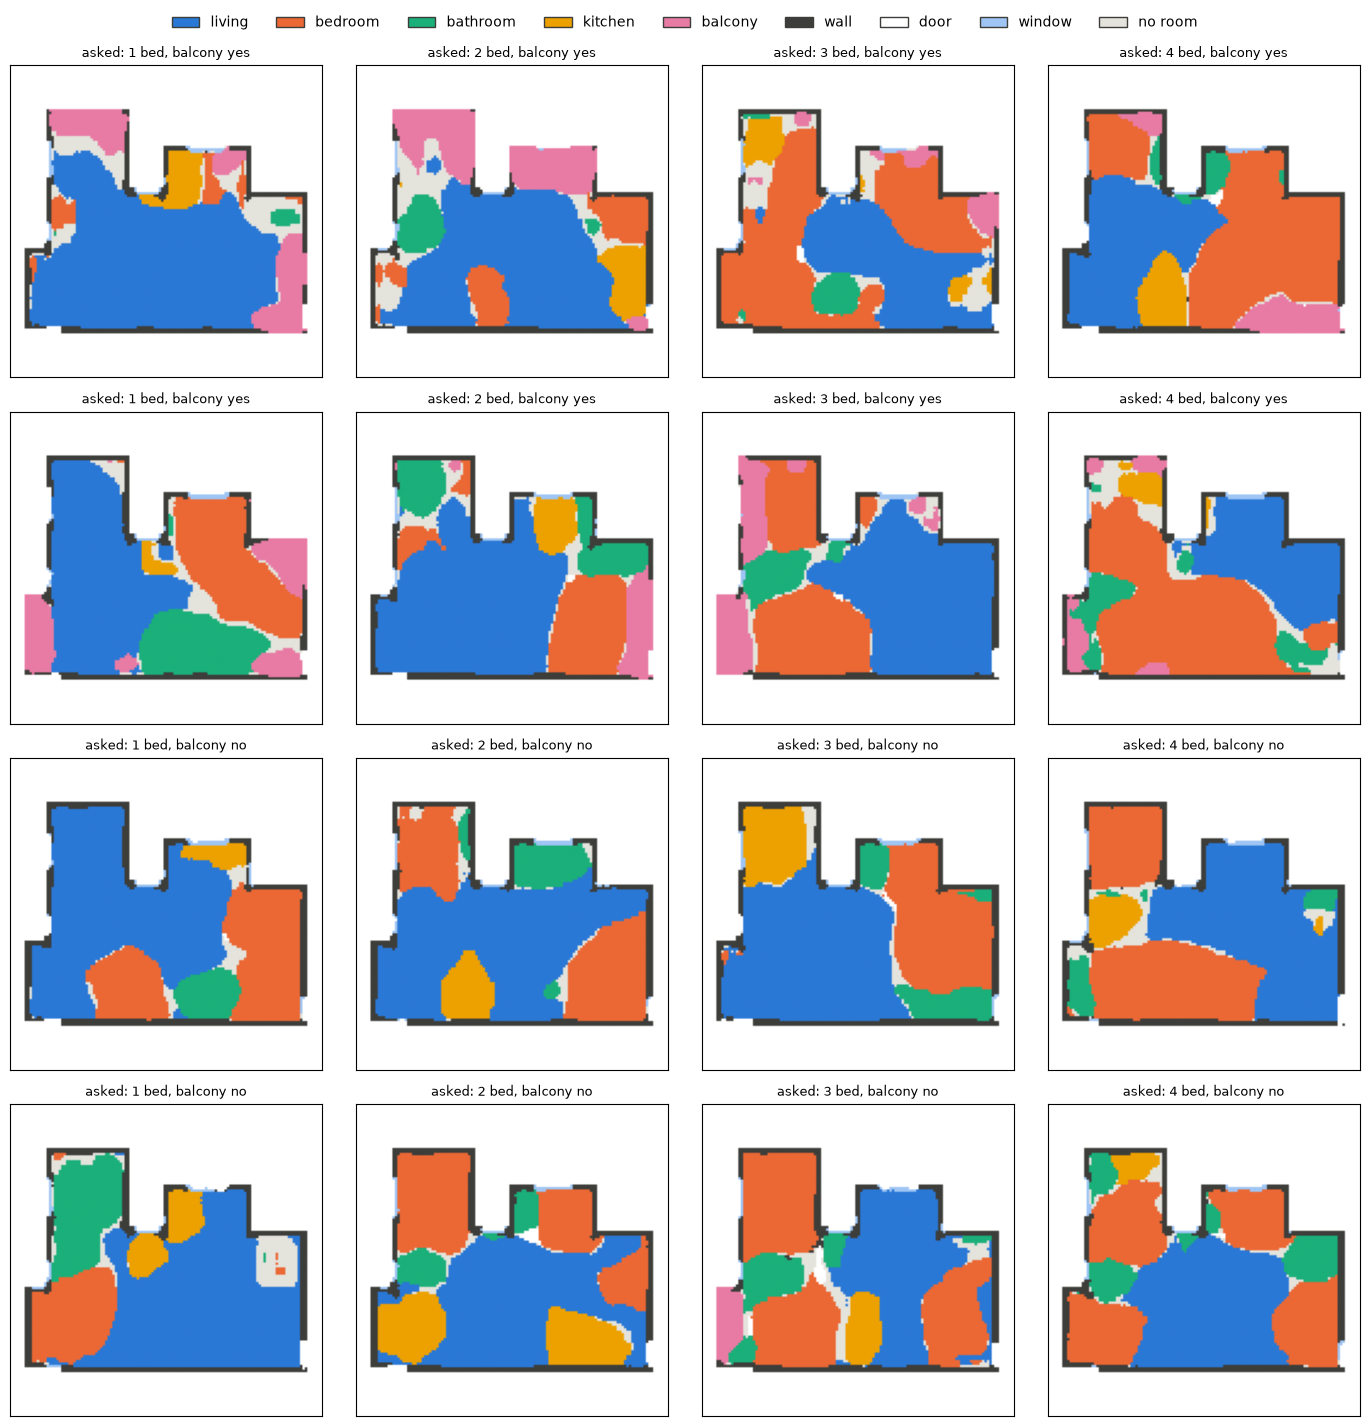

In [25]:
# Following the request: ONE silhouette, ask for 1 to 4 bedrooms, with and without a balcony
r = val_rows[0]
asks = [(b, y) for y in [1, 0] for b in [1, 2, 3, 4]]
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for k, (b, y) in enumerate(asks):
    row, col = 2 * (k // 4), k % 4
    options = generate(cvae, sil_u8[r], condition_vector(b, y, lib.loc[r, "area_m2"]), n=2, seed=k)
    for j in range(2):
        ax = axes[row + j, col]
        ax.imshow(to_color(options[j], sil_u8[r]))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"asked: {b} bed, balcony {'yes' if y else 'no'}", fontsize=9)
fig.legend(handles=MAP_LEGEND, loc="upper center", ncol=len(MAP_LEGEND), frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
save_fig("45_cvae_follows_request")
plt.show()

In [26]:
# The numbers on 200 validation plans (3 options each). First the counter itself, on the REAL maps:
# if the counter is wrong there, it is not the model's fault.
check_rows = np.random.default_rng(2).choice(val_rows, size=min(200, len(val_rows)), replace=False)
real_right = np.mean([min(count_in_map(maps_u8[r], lib.loc[r, "m_per_px"])[0], BED_MAX) == min(int(lib.loc[r, "bedrooms"]), BED_MAX)
                      for r in check_rows])
final = request_score(cvae, check_rows)

asked, got = [], []
for k, r in enumerate(check_rows):
    for o in generate(cvae, sil_u8[r], conds[r], n=3, seed=k):
        asked.append(min(int(lib.loc[r, "bedrooms"]), BED_MAX))
        got.append(min(count_in_map(o, lib.loc[r, "m_per_px"])[0], 6))

# How many of the 32 code numbers does the model use? (mean KL above 0.05 per number)
with torch.no_grad():
    x, s, c = to_device(maps_t[check_rows], sil_t[check_rows], cond_t[check_rows])
    mu, logvar = cvae.eval().encode(x, s, c)
    kl_per_number = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp())).mean(0).cpu().numpy()

summary = pd.Series({"counter check: real maps, bedrooms right": real_right,
                     "invented: bedrooms right": final["bedrooms_right"],
                     "invented: bedrooms right ±1": float(np.mean(np.abs(np.array(got) - np.array(asked)) <= 1)),
                     "invented: balcony as asked": final["balcony_right"],
                     "options differ (share of pixels)": final["different"],
                     "code numbers in use (of 32)": int((kl_per_number > 0.05).sum())})
print(summary.round(3).to_string())
pd.crosstab(pd.Series(asked, name="asked"), pd.Series(got, name="invented (counted)"))

counter check: real maps, bedrooms right     0.975
invented: bedrooms right                     0.373
invented: bedrooms right ±1                  0.862
invented: balcony as asked                   0.992
options differ (share of pixels)             0.583
code numbers in use (of 32)                 32.000


invented (counted),0,1,2,3,4
asked,,,,,
1,14,47,8,0,0
2,4,119,139,11,0
3,1,54,120,36,8
4,0,7,13,11,2
5,0,0,3,1,2


### What to look at
- **The trial table:** which `BETA` won, and why (score, bedrooms, how different the options are)?
- **Rebuilt:** close to the real maps? Which rooms get lost?
- **Invented:** do the 5 options look like **plans** (rooms with walls between them, doors, windows on the outer walls), or like blurry patches? Are they **different** from each other?
- **Following the request:** more bedrooms when we ask for more? A balcony only when we ask?
- **Numbers:** the counter check shows how far we can trust the counting. The table shows, for each asked number of bedrooms, how many the model drew.

# 6. Save for the next steps

In [27]:
config = {
    "model": "LayoutCVAE: conditional VAE, decoder sees the silhouette at 8, 16, 32, 64 and 128 pixels",
    "weights": "layout_cvae.pt",
    "latent_dim": LATENT,
    "image_size": IMG,
    "channels": CHANNELS,
    "silhouette": "floor (inner) + walls + balconies, gaps closed by 1 unit; values 0-1 inside",
    "preprocessing": (f"turn 90 degrees if taller than wide; move the corner to (0, 0); scale to fit {DRAW}x{DRAW} "
                      f"with a {MARGIN:.0%} margin, centred, y axis pointing down; fill; shrink to {IMG}x{IMG} "
                      f"with cv2.INTER_AREA; divide by 255"),
    "condition": {"bedrooms_onehot": [1, 2, 3, 4, f"{BED_MAX}+"], "balcony": "0 or 1",
                  "area": "log(silhouette m2), minus area_mean, divided by area_std",
                  "area_mean": AREA_MEAN, "area_std": AREA_STD},
    "generate": "z = random normal (latent_dim numbers); output = decode(z, silhouette, condition)",
    "beta": BETA,
    "free_bits": FREE_BITS,
    "epochs_trained": len(history),
    "best_epoch": best_epoch,
    "check_on_validation": {k: float(v) for k, v in summary.items()},
}
(MODEL_DIR / "layout_cvae_config.json").write_text(json.dumps(config, indent=2, default=float))
for path in sorted(MODEL_DIR.glob("*")):
    print(f"{str(path):55s} {path.stat().st_size / 1e6:7.2f} MB")

..\models\layout_generator\layout_cvae.pt                  6.08 MB
..\models\layout_generator\layout_cvae_config.json         0.00 MB
..\models\layout_generator\layout_cvae_training.json       0.01 MB
..\models\layout_generator\room_rules.json                 0.00 MB


In [28]:
# Is the bedroom AREA right, even when the COUNT is wrong?
# If yes: the model draws the right amount of bedroom space, but merges bedrooms (no wall between them).
rows_ = []
for k, r in enumerate(check_rows):
    asked_b = min(int(lib.loc[r, "bedrooms"]), BED_MAX)
    px_m2 = lib.loc[r, "m_per_px"] ** 2
    real = maps_u8[r].astype(np.float32) / 255
    real_m2 = ((real[:5].argmax(0) == 1) & (real[:5].max(0) > 0.5)).sum() * px_m2
    for o in generate(cvae, sil_u8[r], conds[r], n=3, seed=k).numpy():
        invented_m2 = ((o[:5].argmax(0) == 1) & (o[:5].max(0) > 0.5)).sum() * px_m2
        rows_.append({"asked bedrooms": asked_b, "real: bedroom m²": real_m2, "invented: bedroom m²": invented_m2})
pd.DataFrame(rows_).groupby("asked bedrooms").median().round(1)

,real: bedroom m²,invented: bedroom m²
asked bedrooms,,
1,14.9,14.5
2,38.5,30.5
3,60.6,50.3
4,95.7,75.5
5,102.9,90.0


### What we see (bedroom area)

| asked bedrooms | real: bedroom m² | invented: bedroom m² | invented m² per bedroom |
|---|---|---|---|
| 1 | 14.9 | 14.5 | 14.5 |
| 2 | 38.5 | 30.5 | 15.3 |
| 3 | 60.6 | 50.3 | 16.8 |
| 4 | 95.7 | 75.5 | 18.9 |
| 5 | 102.9 | 90.0 | 18.0 |

- **The model does follow the request:** the more bedrooms we ask for, the more bedroom space it draws, about 15–20 m² more per bedroom.
- **This confirms the explanation:** the area is right, the **count** is wrong because bedrooms side by side merge (no wall between them).
- The invented bedroom area is 15–20% smaller than the real one: part of the space stays grey ("no room") or blurry at the edges. In step 3 the grey areas are given to the neighbouring room.
- **Decision: no new training.** In step 3 we know how many bedrooms were asked, so we **split** the large bedroom patches along their long side until there are exactly that many bedrooms. An option where a bedroom would be smaller than 9 m² is dropped.